# 05 · Designing the A/B test

Phase 4 ranked the candidates offline, but its own check could not confirm that re-ordering
changes whether a booking happens (its order-luck slope had an interval including zero). So the
decision goes to an online test. This notebook sizes it.

**Arms** (agreed before sizing):

| Arm | Ranking | Why it is in the test |
|---|---|---|
| C | Current production ranking | Control. The offline data cannot score it, so every candidate is compared with it online |
| T1 | Reviews first | The pick of the pre-declared rule (`reports/decision_rule.md`) |
| T2 | Model blend, λ = 0.3 | Beat reviews first on bookings *and* value offline, but was found after looking, so it is labelled exploratory |

Cheapest first, the original proposal, is not tested: offline it lost to reviews first on both
bookings and booking value.

In [1]:
import sys
from pathlib import Path


def _project_root() -> Path:
    """The folder holding src/hotelrank, wherever the script or notebook was started."""
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "hotelrank" / "__init__.py").exists():
            return p
    for marker in here.glob("*/src/hotelrank/__init__.py"):
        return marker.parents[2]
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hotelrank import abtest, audit, position
from hotelrank.data import FIGURES_DIR, ROOT as PROJECT_ROOT, load
from hotelrank.records import read_metrics, show_verdict, write_metrics

COLUMNS = ["srch_id", "position", "random_bool", "click_bool", "booking_bool", "price_usd", "prop_starrating",
           "prop_review_score", "prop_brand_bool", "prop_location_score1", "promotion_flag", "prop_id",
           "srch_length_of_stay"]
df, SOURCE = load(COLUMNS)
flags_path = PROJECT_ROOT / "data" / "interim" / "search_flags.parquet"
if SOURCE == "real" and flags_path.exists():
    flags = pd.read_parquet(flags_path)
else:
    flags = audit.price_flags(df, audit.per_search(df)).reset_index().rename(columns={"index": "srch_id"})
x = position.analysis_sample(df, flags)
del df
x = x[x["random_bool"].astype(bool)]
x = x.assign(value=x["booking_bool"] * x["price_usd"].astype(float) * x["srch_length_of_stay"].astype(float))
per_search = x.groupby("srch_id").agg(booked=("booking_bool", "max"), value=("value", "sum"))
p04 = read_metrics("04_policy_evaluation")  # the phase-4 record committed with the repo
print(SOURCE, f"{len(per_search):,} random-order searches")

real 114,681 random-order searches


## 1. Inputs

**Baseline.** Booking rate and booking value per search in the randomly ordered searches. The
data holds only searches with at least one click, so every number here is *per clicked
search* (see section 6 for what that means in production).

**Effect to detect.** Phase 4 gives model-implied lifts. Its order-luck check says the realized
effect of re-ordering was about a third of what the model predicts (and could be zero; the exact slope is read from the phase-4 record). The test is
sized on the *discounted* lift of T2 over T1, the smallest comparison that decides between the
candidates; the undiscounted lift is shown for reference.

In [2]:
P0 = float(per_search["booked"].mean())
value_raw = abtest.per_search_value_stats(per_search["value"].to_numpy())
value_cap = abtest.per_search_value_stats(per_search["value"].to_numpy(), cap_quantile=0.99)

pol = p04["policies"]
blend = next(f for f in p04["frontier_exploratory"] if abs(f["lambda"] - 0.3) < 1e-9)
logged = pol["logged_random_order"]["bookings_per_search"]
b1 = pol["B1_reviews_first"]
SLOPE = p04["evaluator"]["order_luck_slope"]["slope"]
lifts = pd.DataFrame({"offline": {
    "T1 reviews first vs random order": b1["bookings_per_search"] / logged - 1,
    "T2 blend vs random order": blend["bookings"] / logged - 1,
    "T2 blend vs T1 reviews first": blend["bookings"] / b1["bookings_per_search"] - 1,
}})
lifts["discounted"] = lifts["offline"] * SLOPE
inputs = {"baseline_booking_rate": round(P0, 8),
          "value_raw": {k: (round(v, 6) if v is not None else None) for k, v in value_raw.items()},
          "value_capped_p99": {k: (round(v, 6) if v is not None else None) for k, v in value_cap.items()},
          "order_luck_slope": SLOPE, "blend_value_vs_t1": round(blend["value"] / b1["value_per_search_usd"] - 1, 5)}
print(inputs)
lifts.round(4)

{'baseline_booking_rate': 0.13258517, 'value_raw': {'mean': 38.692395, 'sd': 168.060916, 'cv': 4.343513, 'cap': None}, 'value_capped_p99': {'mean': 37.663215, 'sd': 149.22223, 'cv': 3.962015, 'cap': 1929.468}, 'order_luck_slope': 0.3713, 'blend_value_vs_t1': 0.00543}


,offline,discounted
T1 reviews first vs random order,0.0380,0.0141
T2 blend vs random order,0.1354,0.0503
T2 blend vs T1 reviews first,0.0938,0.0348


## 2. Design choices, fixed before the sample size is computed

- **Unit:** randomize by visitor, analyse per search. The data has no visitor id, so the
  numbers below assume searches are independent; repeat searches by the same visitor make the
  real requirement larger (a design effect, estimated from the A/A period).
- **Allocation:** equal thirds.
- **Comparisons:** T1 vs C, T2 vs C and T2 vs T1, sized at α = 0.05 / 3 each (Bonferroni),
  two-sided, power 80%. The analysis uses Holm's step-down, which keeps the same 5% family-wise
  error and is never less powerful.
- **Primary metric:** booked (0/1) per search. **Guardrail:** booking value per search may not
  fall more than 2% (the margin of the phase-4 rule), one-sided α = 0.025, with value capped at
  the 99th percentile of booked value; the cap is fixed now, before any test data exists. An arm
  ships only if it wins on bookings *and* passes the guardrail; requiring both is an
  intersection-union test, so the guardrail needs no further multiplicity adjustment.

In [3]:
ALPHA = 0.05 / 3
POWER = 0.8
MARGIN = 0.02
anchor = lifts.loc["T2 blend vs T1 reviews first"]  # offline, discounted
grid = sorted({0.02, 0.03, 0.05, 0.075, 0.10, round(float(anchor["discounted"]), 4), round(float(anchor["offline"]), 4)})
booking_n = pd.DataFrame({"relative lift": grid,
                          "searches per arm": [abtest.n_two_proportions(P0, g, ALPHA, POWER) for g in grid]})
booking_n["note"] = ["discounted T2 vs T1" if abs(g - anchor["discounted"]) < 1e-4 else
                     "offline T2 vs T1" if abs(g - anchor["offline"]) < 1e-4 else "" for g in grid]
N_PRIMARY = abtest.n_two_proportions(P0, float(anchor["discounted"]), ALPHA, POWER)
booking_n

,relative lift,searches per arm,note
0,0.0200,345357,
1,0.0300,154133,
2,0.0348,114774,discounted T2 vs T1
3,0.0500,55948,
4,0.0750,25120,
5,0.0938,16182,offline T2 vs T1
6,0.1000,14273,


## 3. The value guardrail

Booking value per search is mostly zeros with a long right tail, so its variance is large
relative to its mean. Showing that value has not dropped by more than 2% can need more traffic
than detecting the booking lift. Capping at the 99th percentile cuts the variance. The second
table shows the lever the business owns: how much value loss it is willing to rule out.

In [4]:
guard = pd.DataFrame([
    {"value metric": label, "cv": s["cv"],
     "per arm, true difference 0": abtest.n_noninferiority_mean(s["mean"], s["sd"], MARGIN, 0.025, POWER),
     "per arm, true difference = T2's offline value gain":
         abtest.n_noninferiority_mean(s["mean"], s["sd"], MARGIN, 0.025, POWER, max(inputs["blend_value_vs_t1"], 0.0))}
    for label, s in (("raw", value_raw), ("capped at p99", value_cap))]).set_index("value metric")
N_GUARD = int(guard.loc["capped at p99", "per arm, true difference 0"])
guard.round(3)

,cv,"per arm, true difference 0","per arm, true difference = T2's offline value gain"
value metric,,,
raw,4.344,740389,457960
capped at p99,3.962,616042,381046


In [5]:
margins = pd.DataFrame({"margin": [0.02, 0.03, 0.05]})
margins["per arm (capped, true difference 0)"] = [abtest.n_noninferiority_mean(value_cap["mean"], value_cap["sd"], m, 0.025, POWER)
                                                  for m in margins["margin"]]
margins

,margin,"per arm (capped, true difference 0)"
0,0.02,616042
1,0.03,273797
2,0.05,98567


## 4. Checking the formula by simulation

4,000 simulated tests at the computed size: the share that reject should be about 80%.

In [6]:
sim_power = abtest.simulate_power(P0, float(anchor["discounted"]), N_PRIMARY, ALPHA, n_sim=4000, seed=5)
print(f"closed form 0.80, simulated {sim_power:.3f}")

closed form 0.80, simulated 0.798


## 5. How long it runs

Per arm, the test needs the larger of the two requirements. Traffic is not in the data, so
the duration is shown for a few illustrative volumes of clicked searches entering the test per
day. Whatever the volume, the test runs at least two full weeks so every weekday is seen twice.

In [7]:
N_ARM = max(N_PRIMARY, N_GUARD)
TOTAL = 3 * N_ARM
duration = pd.DataFrame({"clicked searches per day in test": [25_000, 100_000, 250_000]})
duration["days for sample"] = np.ceil(TOTAL / duration.iloc[:, 0]).astype(int)
duration["days to run"] = np.maximum(duration["days for sample"], 14)
mde_at_n = abtest.mde_two_proportions(P0, N_ARM, ALPHA, POWER)
print(f"per arm {N_ARM:,} (booking needs {N_PRIMARY:,}, guardrail {N_GUARD:,}); total {TOTAL:,}; "
      f"booking MDE at that size {mde_at_n:.2%}")
duration

per arm 616,042 (booking needs 114,487, guardrail 616,042); total 1,848,126; booking MDE at that size 1.50%


,clicked searches per day in test,days for sample,days to run
0,25000,74,74
1,100000,19,19
2,250000,8,14


## 6. What the sizes assume

- **Clicked searches only.** In production the analysis population must be fixed before
  treatment can change it, so it is every search that shows results, not only those with a
  click (a ranking changes who clicks). With click-through rate c, the requirement in all
  searches is roughly the per-clicked-search requirement divided by c, if the relative lift is
  unchanged.
- **Baseline from random order.** Production ranks better than random, so its booking rate is
  higher than the baseline used here; a higher rate needs fewer searches for the same relative
  lift, which makes these numbers conservative on that count.
- **Independent searches.** See the unit note in section 2.

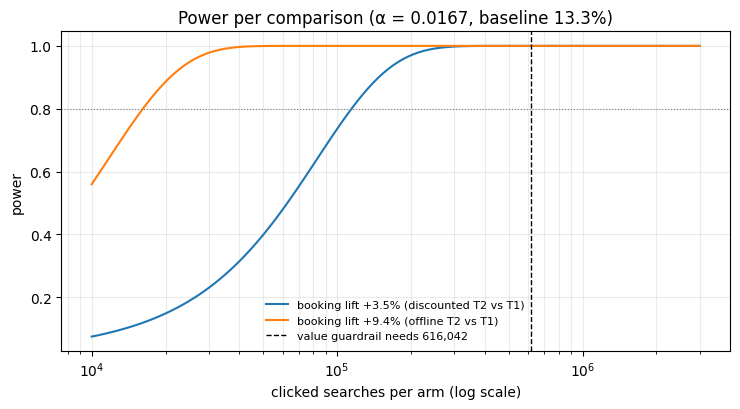

In [8]:
ns = np.unique(np.geomspace(1e4, 3e6, 120).astype(int))
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for g, label, colour in ((float(anchor["discounted"]), "discounted T2 vs T1", "#1f77b4"),
                         (float(anchor["offline"]), "offline T2 vs T1", "#ff7f0e")):
    ax.plot(ns, [abtest.power_two_proportions(P0, g, int(n), ALPHA) for n in ns], color=colour,
            label=f"booking lift {g:+.1%} ({label})")
ax.axhline(POWER, color="grey", ls=":", lw=0.8)
ax.axvline(N_GUARD, color="black", ls="--", lw=1, label=f"value guardrail needs {N_GUARD:,}")
ax.set_xscale("log")
ax.set(xlabel="clicked searches per arm (log scale)", ylabel="power",
       title=f"Power per comparison (α = {ALPHA:.4f}, baseline {P0:.1%})")
ax.legend(frameon=False, fontsize=8)
ax.grid(alpha=0.25, which="both")
fig.tight_layout()

In [9]:
record = {
    "design": {"arms": ["C current ranking", "T1 reviews first", "T2 blend lambda 0.3 (exploratory)"],
               "alpha_per_comparison": round(ALPHA, 6), "power": POWER, "value_margin": MARGIN,
               "comparisons": ["T1 vs C", "T2 vs C", "T2 vs T1"], "unit": "visitor (searches analysed)"},
    "inputs": inputs,
    "lifts": {k: {c: round(float(v), 10) for c, v in r.items()} for k, r in lifts.iterrows()},
    "booking_n": booking_n.to_dict(orient="records"),
    "guardrail_n_by_margin": {f"{m:.0%}": int(n) for m, n in margins.itertuples(index=False)},
    "guardrail_n": {k: {c: (round(float(v), 4) if c == "cv" else int(v)) for c, v in r.items()} for k, r in guard.iterrows()},
    "n_primary": N_PRIMARY, "n_guardrail": N_GUARD, "n_per_arm": N_ARM, "n_total": TOTAL,
    "mde_at_n_per_arm": round(mde_at_n, 5), "simulated_power": round(sim_power, 4),
    "duration_days": duration.to_dict(orient="records"),
}
out_path = write_metrics("05_ab_test_design", record, SOURCE)
print("wrote", out_path.relative_to(PROJECT_ROOT) if SOURCE == "real" else out_path.name)
if SOURCE == "real":
    fig.savefig(FIGURES_DIR / "05_ab_test_power.png", dpi=150, bbox_inches="tight")

wrote reports\metrics\05_ab_test_design.json


## Verdict

How big the confirming test has to be, and what drives that size. The verdict is rendered from
`record`, the same dictionary written to `reports/metrics/05_ab_test_design.json`.

In [10]:
lt = record["lifts"]["T2 blend vs T1 reviews first"]
ci = p04["evaluator"]["order_luck_slope"]["ci"]
binding = "the value guardrail" if record["n_guardrail"] > record["n_primary"] else "the booking comparison"
verdict = [
    f"Three arms: the current ranking (control), reviews first (the rule's pick) and the λ = 0.3 blend "
    f"(exploratory). Each of the three pairwise comparisons is tested at α = {ALPHA:.4f}, power {POWER:.0%}.",
    f"The test is sized on the gap between the two candidates: {lt['offline']:+.1%} offline, discounted "
    f"to {lt['discounted']:+.1%} because phase 4's order-luck check put the realized effect of re-ordering at "
    f"about {SLOPE:.2f} of the model's prediction (95% CI {ci[0]:.2f} to {ci[1]:.2f}). Detecting that lift on a {P0:.1%} booking rate needs {record['n_primary']:,} clicked searches per arm.",
    f"The value guardrail (no more than a {MARGIN:.0%} drop, value capped at the 99th percentile) needs "
    f"{record['n_guardrail']:,} per arm; uncapped it would need "
    f"{record['guardrail_n']['raw']['per arm, true difference 0']:,}. {binding[0].upper() + binding[1:]} sets the size; "
    f"accepting a 5% margin instead would cut it to {record['guardrail_n_by_margin']['5%']:,}, a call for the business.",
    f"Per arm {record['n_per_arm']:,}, total {record['n_total']:,} clicked searches; at that size the smallest "
    f"detectable booking lift is {record['mde_at_n_per_arm']:.1%}. Simulation gives power {record['simulated_power']:.2f} "
    "for the closed-form size.",
    "Sizes are per clicked search with searches treated as independent; in production the population is every "
    "search with results and the unit is the visitor, which both raise the requirement.",
]
show_verdict("Phase 5 verdict: A/B test design", verdict,
             "the decision memo (`reports/decision_memo.md`) turns phases 1-5 into a recommendation.")

### Phase 5 verdict: A/B test design

1. Three arms: the current ranking (control), reviews first (the rule's pick) and the λ = 0.3 blend (exploratory). Each of the three pairwise comparisons is tested at α = 0.0167, power 80%.
2. The test is sized on the gap between the two candidates: +9.4% offline, discounted to +3.5% because phase 4's order-luck check put the realized effect of re-ordering at about 0.37 of the model's prediction (95% CI -0.28 to 1.02). Detecting that lift on a 13.3% booking rate needs 114,487 clicked searches per arm.
3. The value guardrail (no more than a 2% drop, value capped at the 99th percentile) needs 616,042 per arm; uncapped it would need 740,389. The value guardrail sets the size; accepting a 5% margin instead would cut it to 98,567, a call for the business.
4. Per arm 616,042, total 1,848,126 clicked searches; at that size the smallest detectable booking lift is 1.5%. Simulation gives power 0.80 for the closed-form size.
5. Sizes are per clicked search with searches treated as independent; in production the population is every search with results and the unit is the visitor, which both raise the requirement.

**Next:** the decision memo (`reports/decision_memo.md`) turns phases 1-5 into a recommendation.